## Course Announcements

Due Sunday: 
- Q4
- A3
- Project Proposal <- accept repo invite; talk with your group!

Notes:
- summarized previous project reviews - added to your [wk3 discussion section notes](https://docs.google.com/document/d/1m8OFa-9GTEMbKRePPbXggkc0KZV0lZIFCuafVvTYow8/edit?tab=t.xuspn2i0csk)
- Tidy Data in lecture 03; Project Documentation: [where to find data](https://github.com/COGS108/Projects/blob/fa26/FinalProject_Guidelines.md#how-to-find-datasets)

### San Diego Co$tS Data Science Question (Summary)

When brainstorming costs, y'all thought about:
- Housing and rent (about 40%) came up most, often alongside supply and demand (“high demand, limited supply”).
- Location, beach and coast (about 30%): many treated the location as the answer itself, as in “it’s by the beach.”
- Income and wages (about 19%), usually framed as whether pay keeps up with costs.
- Weather (about 18%).
- Everyday costs (about 18% each for groceries/food and for gas, transportation and utilities). Several named SDG&E specifically.
- Taxes, policy and government (about 15%).
- Jobs and industry (about 14%), with tech and biotech mentioned by name.
- Population, demand and migration (about 14%).
- UCSD, students and education (about 10%).
- Less common ideas: tourism, inflation, the military, the border, Airbnb, retirees, “old money,” corporate or investor buyers, and homelessness.

15% of y'all criticized the prompt (this was great!)
- compared to what?
- cause is hard to prove
- "live" - vacation rentals included? unhoused people?
- assumes it is expensive

Some strong student submissions:

- *“Within the City of San Diego, do ZIP codes that permitted more new housing units per 1,000 residents between 2015 and 2023 show smaller increases in median rent over the same period, after controlling for change in median household income?”*
- *“How has the median monthly rent for a 1-bedroom apartment in San Diego changed from 2015 to 2025, and how does that compare to the growth in median household income over the same period?”*

Creative ideas (unique takes; need more time to nail down the data science question):
- *“Does the perceived aesthetic of San Diego as portrayed by TikTok affect why people would move to coastal San Diego”*
- *“How does the price of utilities in San Diego compare to neighboring cities and how does a monopolizing company (like SDG&E) correlate to increased utility prices throughout Californian cities?”*
- *“How much does the rent increase after the investors in Bay Area started investing the housing in San Diego?”* 
- *“Per Capita, what is the grocery price for a 12 pack egg carton at the Ralphs in La Jolla Village compared to the national average.”* <- Very specific, measurable, but *too* narrow

# EDA: Exploratory Data Analysis

<div class="alert alert-success">
For more information on this topic, check out: (1) Jake VanderPlas' <a href="https://jakevdp.github.io/PythonDataScienceHandbook/" class="alert-link">Python Data Science Handbook</a> and (2) Berkeley's <a href="https://learningds.org/intro.html" class="alert-link">Learning Data Science</a>.
</div>

## Exploratory data analysis (EDA)

> an open-ended approach to completely and fully understand your dataset.

It requires a state of flexibility and a willingness to look for both:
- artifacts in the data we anticipate exist 
- artifacts that we don't expect / believe are there

## Contents

Lost track of where we are? Click a section to jump to it. (In JupyterLab, the table of contents sidebar, the bulleted-list icon on the left, shows the same outline and highlights the section you're in.)

- [1. Setup](#s1)
- [2. Motivating Question(s)](#s2)
- [3. The Data](#s3) · [3a. Tidy Data Rules (Review)](#s3a)
- [4. EDA: What We Know So Far](#s4)
- [5. Missingness](#s5)
- [6. Cleaning](#s6) · [6a. Return to Missingness](#s6a) · [6b. The Cleaned Data](#s6b)
- [7. Aside: Anscombe's Quartet](#s7)
- [8. Shape](#s8) · [8a. Outliers](#s8a)
- [9. Central Tendency](#s9) · [9a. Mean](#s9a) · [9b. Median](#s9b) · [9c. Mode](#s9c) · [9d. How Did Y'all Do?](#s9d) · [9e. Why Central Tendency Isn't Enough](#s9e)
- [10. Variability](#s10) · [10a. Range](#s10a) · [10b. IQR](#s10b) · [10c. Variance & Standard Deviation](#s10c)
- [11. Descriptive Tables](#s11)
- [12. Relationships Between Variables](#s12)
- [13. EDA: A Recap](#s13)

## 1. Setup <a id="s1"></a>

In [1]:
# Import seaborn and apply its plotting styles
import seaborn as sns
sns.set_theme(style="white", font_scale=1.5)

# import matplotlib
import matplotlib.pyplot as plt
# set plotting size parameter
plt.rcParams['figure.figsize'] = (10, 5)

# make sure pandas & numpy are imported
import pandas as pd
import numpy as np

# import cleaning code
from src.clean_estimates import clean_hair, clean_area, clean_days

import warnings
warnings.filterwarnings('ignore')

# improve resolution
# comment this line if erroring on your machine/screen
%config InlineBackend.figure_format = 'retina'

## 2. Motivating Question(s) <a id="s2"></a>

How well do COGS 108 students estimate the following:
- How fast does human hair grow (cm/yr)?
- If every living person stood crammed together side-by-side, how large of an area would they occupy (km²)?
- How many days would it take to walk from San Diego to New York City (assuming no stopping to fix shoes, apply sunscreen, or for sleeping, eating, or other biological needs)?

## 3. The Data <a id="s3"></a>

To walk through these concepts today, we're going to use your responses from after the Data Lecture, where we discussed data intuition and specifically wisdom of the crowds.

In [2]:
# read data into Python
df = pd.read_csv('data/woc_fa26.csv')

In [3]:
# take a look at the data
df

,How fast does human hair grow (cm/yr)?,"If every living person stood crammed together side-by-side, how large of an area would they occupy (km²)?","How many days would it take to walk from San Diego to New York City (assuming no stopping to fix shoes, apply sunscreen, or for sleeping, eating, or other biological needs)?"
0,10,1000,100
1,20 cm / year,"500,000,000 km^2",167
2,7.8,10000000000000,27
3,100,10000,150
4,10,30000,135
...,...,...,...
509,4cm/ye,10000km^2,2000
510,60,13500000,7
511,20 cm per year,3000 square kilometers,5000 kilometers
512,7 cm/yr,150,70


### Question #1

Are these data in the tidy data format?

- A) Yes, these data are ready to analyze
- B) Yes, but there is more work to do before analysis
- C) No, not tidy
- D) Have no idea what you're talking about

https://forms.gle/opLaEDoj83NKhb727 

<img src="QRCodes/08_01.png" width="300">

**Brainstorming**

What considerations do we have to make about these data?

(1PM)
- values of the same type; can be aggregated

(2PM)
- values of the same type
- improve column names for ease of analysis and reading
- what about those NaNs? 

### 3a. Tidy Data Rules (Review) <a id="s3a"></a>

1. Every observation in a row
2. Every variable in a column
3. If multiple tables, column on which to merge

In [4]:
# change column names
df.columns = ['hair_cm_yr', 'area_km2', 'walk_days']

In [5]:
# check type of each Series (column)
df.dtypes

hair_cm_yr    object
area_km2      object
walk_days     object
dtype: object

In [6]:
# determine rows and columns in df
df.shape

(514, 3)

## 4. EDA: What We Know So Far <a id="s4"></a>

At this point...we know:

- granularity
- temporality
- scope
- ~faithfulness

In [7]:
df

,hair_cm_yr,area_km2,walk_days
0,10,1000,100
1,20 cm / year,"500,000,000 km^2",167
2,7.8,10000000000000,27
3,100,10000,150
4,10,30000,135
...,...,...,...
509,4cm/ye,10000km^2,2000
510,60,13500000,7
511,20 cm per year,3000 square kilometers,5000 kilometers
512,7 cm/yr,150,70


### Questions #2-4

Let's check our understanding w/ a few questions...
1. What's the granularity of this dataset? 
2. If we wanted to understand something about all COGS 108 students this quarter, could we do that with these data? 
3. How trustworthy do you find these data (given what you've seen so far)?

https://forms.gle/hDRBMT14MyG7MhKH6

<img src="QRCodes/08_02.png" width="300">

What we don't know (yet)
- missingness
- Single variables: Shape, Central Tendency, Variability
- Relationship across variables

## 5. Missingness <a id="s5"></a>

Data can be missing for all kinds of reasons. It's your job to determine if:
- values are missing at random
- values are missing due to data entry errors
- values are missing due to faulty data collection

In [8]:
# columns with missing values
df.isnull().sum()

hair_cm_yr    1
area_km2      2
walk_days     1
dtype: int64

## 6. Cleaning <a id="s6"></a>

- How fast does human hair grow (cm/yr)?
- If every living person stood crammed together side-by-side, how large of an area would they occupy (km²)?
- How many days would it take to walk from San Diego to New York City (assuming no stopping to fix shoes, apply sunscreen, or for sleeping, eating, or other biological needs)?

In [9]:
# take a look at unique values
df["hair_cm_yr"].unique()

array(['10', '20 cm / year', '7.8', '100', '7', '6', '3', '1', '8.78',
       '14', '5', '8', '4cm', '12', '4', '20cm/yr', '50', '20', '18',
       '10cm / yr', '10/1', '15', '30', '12 cm', '300 cm', '23', '17cm',
       '365', '50cm/yr', '20/yr', '10 cm/yr', '10cm/yr', '2 cm/year',
       '60', '40 cm per year', '20cm', '16', '5 inches a year', '250',
       '24', '10.16 cm/yr', '25', '10^3 cm/yr', '30cm/yr',
       '100cm one year', '42', '8 cm / ye', '5cm/yr', '25cm/yr', '36',
       'Idk', '12cm', '100 cm/yr', '96', '10cm', '40', '200/1', '22cm/yr',
       '100cm/yr', 'Depends my guess 16 cm/yr', '50cm', '32 cm/yr',
       '15cm', '15cm/yr', '3cm/yr', '80', '65cm/yr', '30cm/1yr',
       '12 cm / year', '23 cm/yr', '22', '15.24', '50 cm', '50cm/1yr',
       '10 inches per year', '140cm/yr', '28cm/yr', '6 inches?', '500',
       '25/1', '124', '9.6', '17', '7.5', '13', '12-15 cm/yr', '11',
       '25 cm/yr', '11cm/yr', '100 cm/ yr', '9', '8.5', '10 cm',
       '12cm/yr', '12 cm/year'

In [10]:
df['hair_cm_yr'] = df['hair_cm_yr'].apply(clean_hair)
df['area_km2']   = df['area_km2'].apply(clean_area)
df['walk_days']  = df['walk_days'].apply(clean_days)

### 6a. Return to Missingness <a id="s6a"></a>

Note that after cleaning, we DO have missing values. These would be worth looking into further; being sure we understand *why* they're missing.

In [11]:
# number of missing values by column
df.isnull().sum()

hair_cm_yr     4
area_km2      20
walk_days      2
dtype: int64

In [12]:
null_rows = df.isnull().any(axis=1)
df[null_rows]

,hair_cm_yr,area_km2,walk_days
22,10.00,NaN,10.000000
35,20.00,NaN,6.000000
37,3.00,NaN,5.000000
55,20.00,NaN,365.000000
71,250.00,NaN,24.000000
83,100.00,NaN,30.000000
99,NaN,NaN,220.000000
156,50.00,NaN,30.000000
166,NaN,NaN,300.000000
170,15.24,NaN,67.000000


### 6b. The Cleaned Data <a id="s6b"></a>

In [13]:
df

,hair_cm_yr,area_km2,walk_days
0,10.0,1.000000e+03,100.0
1,20.0,5.000000e+08,167.0
2,7.8,1.000000e+13,27.0
3,100.0,1.000000e+04,150.0
4,10.0,3.000000e+04,135.0
...,...,...,...
509,4.0,1.000000e+04,2000.0
510,60.0,1.350000e+07,7.0
511,20.0,3.000000e+03,NaN
512,7.0,1.500000e+02,70.0


### Think-Pair-Share

What could we have done to avoid these cleaning/wrangling issues?

**Brainstorming**

(2PM)
- Response validation - force number entry in the survey
- Include more instructions - "please don't include units in your response"

**Brainstorming**

(1PM)
- Before giving the survey - for the answer part give explicit instructions not to include units (for example)
- Response Validation: Force the choice to only accept numbers (for example) OR Multiple choice or bins

## 7. Aside: Anscombe's Quartet: A Cautionary Tale <a id="s7"></a>

Code in this example taken from [here](https://matplotlib.org/stable/gallery/specialty_plots/anscombe.html).

In [14]:
x = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5])
y1 = np.array([8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68])
y2 = np.array([9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74])
y3 = np.array([7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73])
x4 = np.array([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8])
y4 = np.array([6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89])

mean=7.50, std=1.94, r=0.82
mean=7.50, std=1.94, r=0.82
mean=7.50, std=1.94, r=0.82
mean=7.50, std=1.94, r=0.82


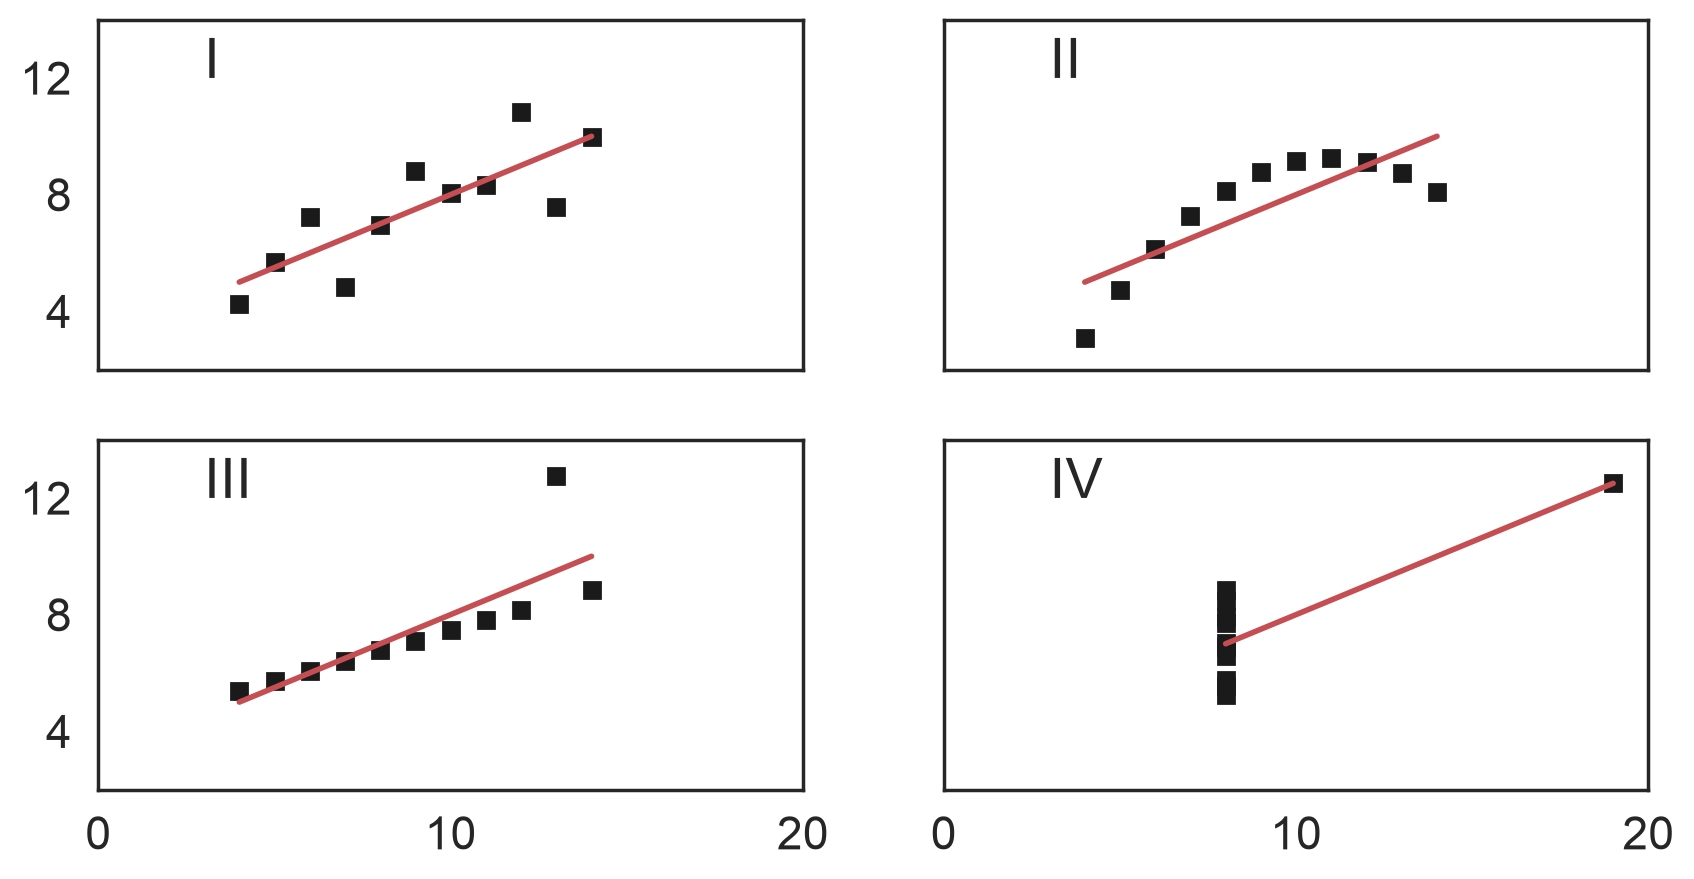

In [15]:
def fit(x):
    return 3 + 0.5 * x

xfit = np.array([np.min(x), np.max(x)])

plt.subplot(221)
plt.plot(x, y1, 'ks', xfit, fit(xfit), 'r-', lw=2)
plt.axis([2, 20, 2, 14])
plt.setp(plt.gca(), xticklabels=[], yticks=(4, 8, 12), xticks=(0, 10, 20))
plt.text(3, 12, 'I', fontsize=20)

plt.subplot(222)
plt.plot(x, y2, 'ks', xfit, fit(xfit), 'r-', lw=2)
plt.axis([2, 20, 2, 14])
plt.setp(plt.gca(), xticks=(0, 10, 20), xticklabels=[],
         yticks=(4, 8, 12), yticklabels=[], )
plt.text(3, 12, 'II', fontsize=20)

plt.subplot(223)
plt.plot(x, y3, 'ks', xfit, fit(xfit), 'r-', lw=2)
plt.axis([2, 20, 2, 14])
plt.text(3, 12, 'III', fontsize=20)
plt.setp(plt.gca(), yticks=(4, 8, 12), xticks=(0, 10, 20))

plt.subplot(224)
xfit = np.array([np.min(x4), np.max(x4)])
plt.plot(x4, y4, 'ks', xfit, fit(xfit), 'r-', lw=2)
plt.axis([2, 20, 2, 14])
plt.setp(plt.gca(), yticklabels=[], yticks=(4, 8, 12), xticks=(0, 10, 20))
plt.text(3, 12, 'IV', fontsize=20)

# verify the stats
pairs = (x, y1), (x, y2), (x, y3), (x4, y4)
for x, y in pairs:
    print('mean=%1.2f, std=%1.2f, r=%1.2f' % (np.mean(y), np.std(y),
          np.corrcoef(x, y)[0][1]))

plt.show()

### Draw the Graph (What a complete EDA is all about!)

## 8. Shape <a id="s8"></a>

- range of values
- overall shape
- outliers? 

### 8a. Outliers <a id="s8a"></a>

Outliers are values that fall outside the typical range of your dataset. These can occur for all types of reasons:

- data entry errors
- poor sampling procedures
- technical or mechanical errors
- unexpected changes in weather
- extreme values
- people giving incorrect information
- etc.

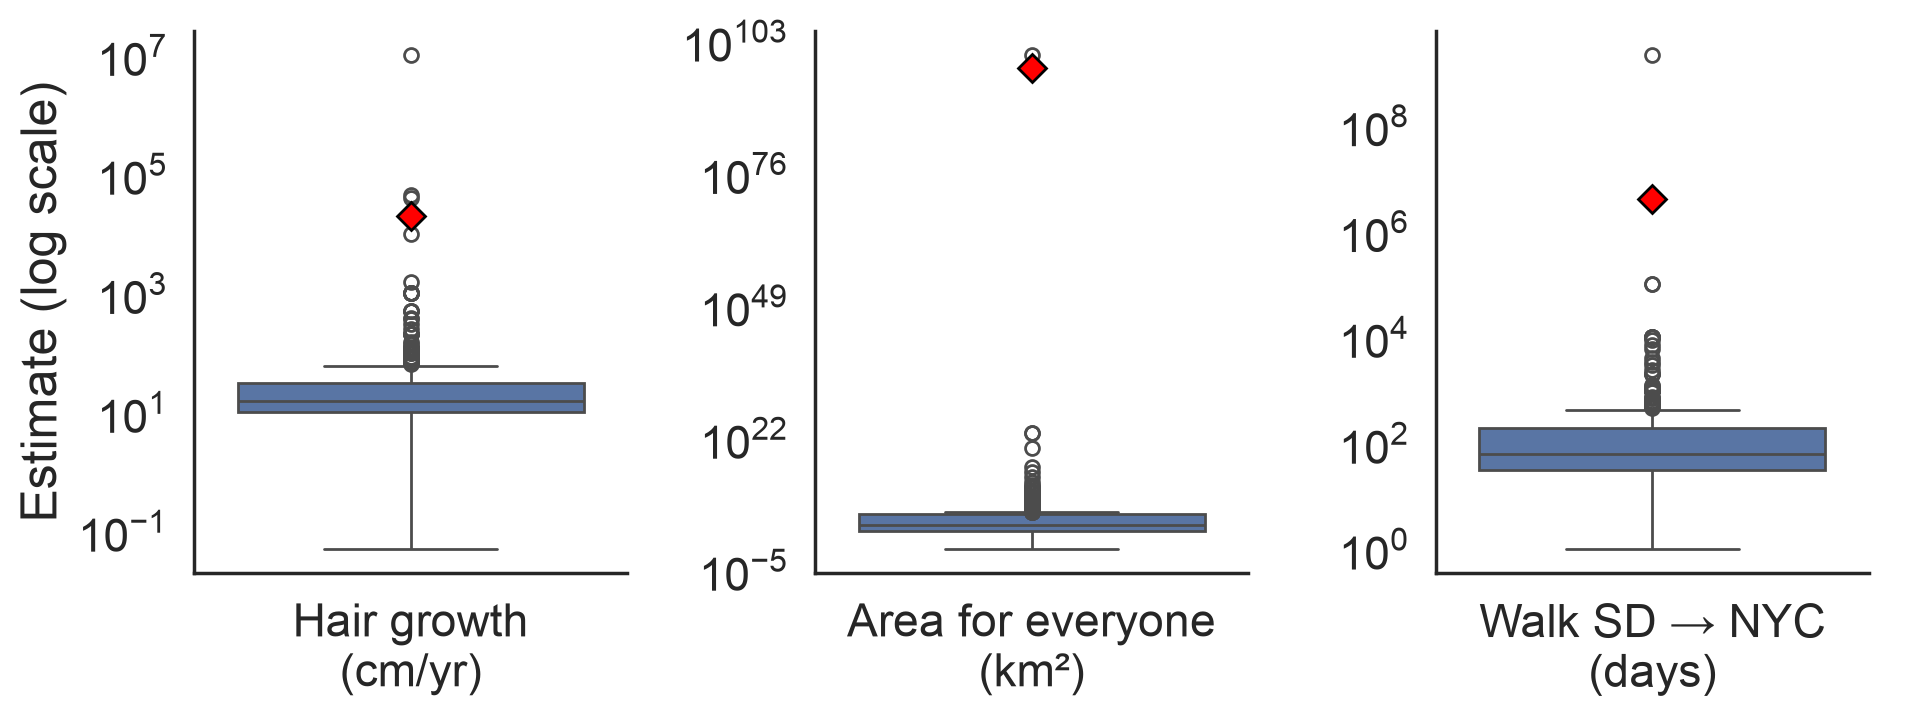

In [16]:
questions = {
    'hair_cm_yr': 'Hair growth\n(cm/yr)',
    'area_km2':   'Area for everyone\n(km²)',
    'walk_days':  'Walk SD → NYC\n(days)',
}

# long format: one row per (question, estimate)
long = df.melt(var_name='question', value_name='estimate').dropna()
long['question'] = long['question'].map(questions)

g = sns.catplot(data=long, x='question', y='estimate', col='question',
                kind='box', sharex=False, sharey=False,
                height=4, aspect=0.8,
                showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'red',
                           'markeredgecolor': 'black', 'markersize': 7})

g.set(yscale='log')
g.set_titles('')                      # the x-axis label already names the question
g.set_axis_labels('', 'Estimate (log scale)')
plt.tight_layout()

<div class="alert alert-danger">
Caution: Observations should only be removed from your dataset if you have a valid reason to do so. If you remove outliers from your dataset, your report should be <b>very</b> clear that you did so.
</div>

### Question #5

Should we remove any outlier values in this dataset? 

- A) Yes
- B) No
- C) ¯\\\_(ツ)\_/¯

### Question #6

Which of the following is the best way to measure the central tendency in these data?

- A) mean
- B) median
- C) mode

https://forms.gle/wNRvouG3a5UAa8Au8

<img src="QRCodes/08_03.png" width="300">

## 9. Central Tendency <a id="s9"></a>

- mean 
- median
- mode

The Central Tendency tells you the 'typical' value for an observation in your dataset.

### 9a. Mean <a id="s9a"></a>


$$ \bar x = \frac{\sum\limits_{i = 1}^N x_i}N  $$


- $x_i$ = ith element of the sample
- $\bar x$ = sample mean
- $N$ = sample size


In [17]:
# check mean for each column
df.mean(numeric_only=True)

hair_cm_yr    1.983875e+04
area_km2      2.024291e+97
walk_days     4.099862e+06
dtype: float64

### 9b. Median <a id="s9b"></a>

In [18]:
# check median for each column
df.median()

hair_cm_yr       15.0
area_km2      13400.0
walk_days        60.0
dtype: float64

### 9c. Mode <a id="s9c"></a>

The most common value.

In [19]:
# check most common value for each column
# (.mode() returns a DataFrame, since there can be ties)
df.mode()

,hair_cm_yr,area_km2,walk_days
0,10.0,10000.0,30.0


### 9d. How Did Y'all Do? <a id="s9d"></a>

How well do COGS 108 students estimate the following:
- How fast does human hair grow (cm/yr)?
- If every living person stood crammed together side-by-side, how large of an area would they occupy (km²)?
- How many days would it take to walk from San Diego to New York City (assuming no stopping to fix shoes, apply sunscreen, or for sleeping, eating, or other biological needs)?

In [20]:
# compare the class's estimates to the actual values
actual = pd.Series({'hair_cm_yr': '15 (~6 in)',
                    'area_km2':   '1,000-10,000',
                    'walk_days':  '~38'})

comparison = pd.DataFrame({'class mean': df.mean(),
                           'class median': df.median(),
                           'class mode':   df.mode().iloc[0],
                           'actual value': actual})
comparison.index = ['Hair growth (cm/yr)', 'Area for everyone (km²)', 'Walk SD → NYC (days)']
comparison

,class mean,class median,class mode,actual value
Hair growth (cm/yr),1.983875e+04,15.0,10.0,15 (~6 in)
Area for everyone (km²),2.024291e+97,13400.0,10000.0,"1,000-10,000"
Walk SD → NYC (days),4.099862e+06,60.0,30.0,~38


Calculating the mean and median of your sample is helpful when dealing with **quantitative variables**.

When working with **categorical variables**, knowing the mode (most common value) is helpful.

### 9e. Aside: Why Central Tendency Doesn't Tell the Whole Story <a id="s9e"></a>

In [21]:
# generate two different normal distributions
# (set a seed so we get the same random numbers every time)
np.random.seed(108)
dist_1 = np.random.normal(5, 2, 1000)
dist_2 = np.random.normal(5, 10, 1000)

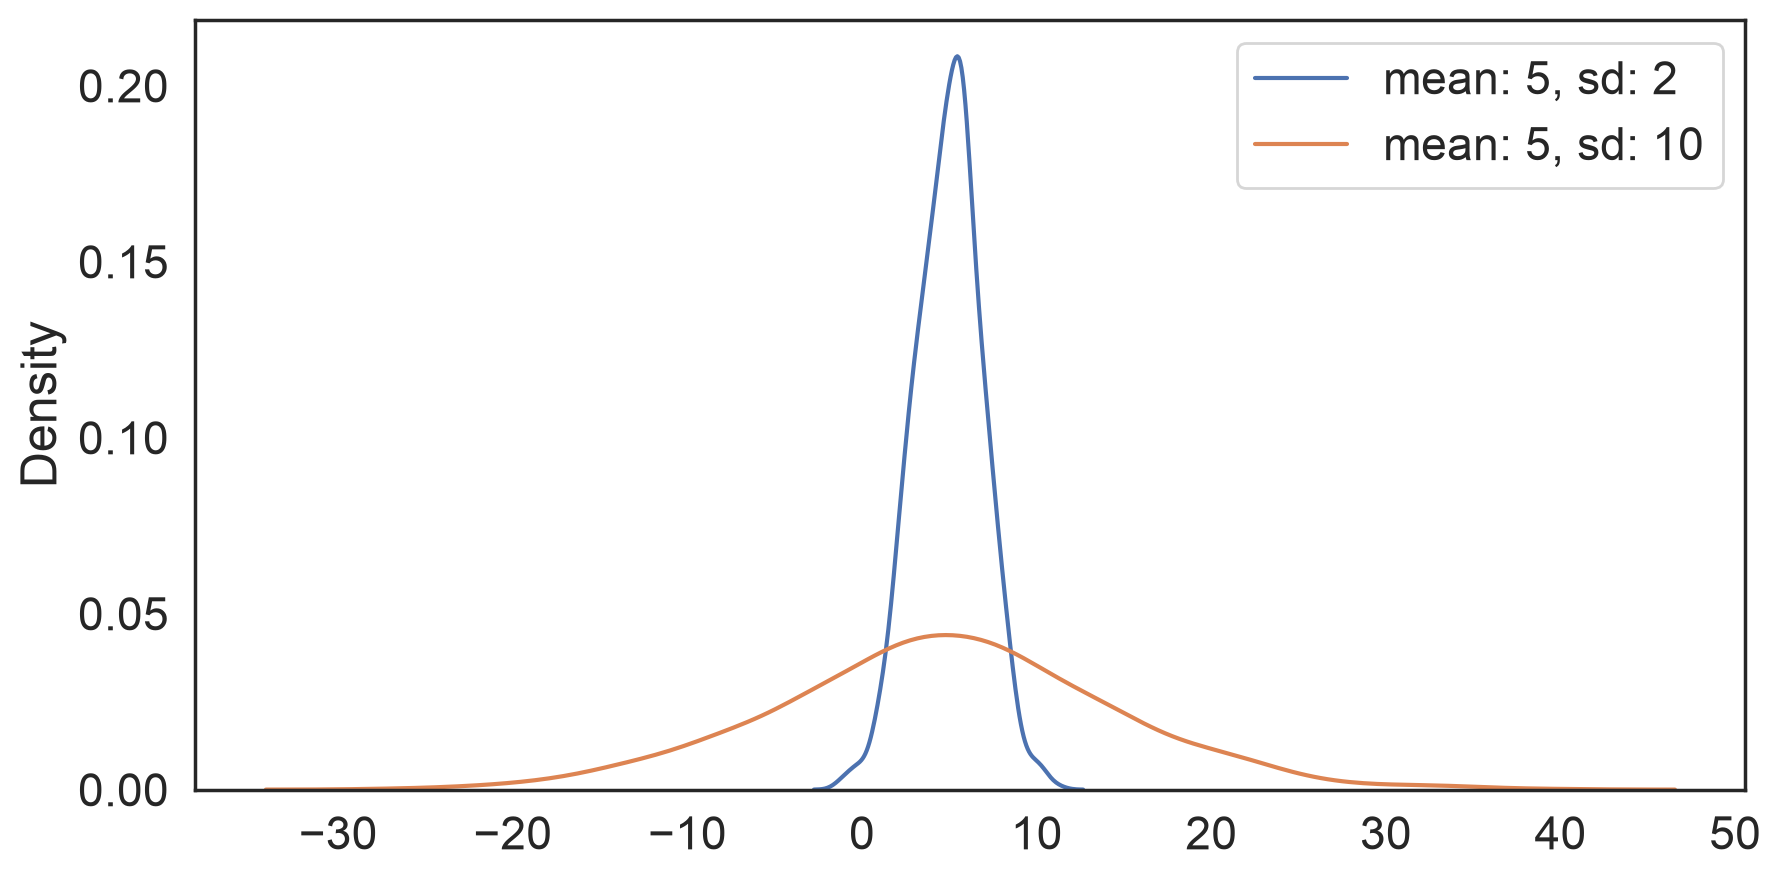

In [22]:
# plot distributions side by side
sns.kdeplot(data=dist_1, label="mean: 5, sd: 2")
sns.kdeplot(data=dist_2, label="mean: 5, sd: 10")
plt.legend();

## 10. Variability <a id="s10"></a>

- Range
- IQR 
- Variance & Standard Deviation

### 10a. Range <a id="s10a"></a>

The highest value minus the lowest value.

In [23]:
# determine the min and max
min_val = df['hair_cm_yr'].min()
max_val = df['hair_cm_yr'].max()
range_vals =  max_val - min_val
print(max_val, '-' , min_val,' = ',  range_vals)

10000000.0 - 0.05  =  9999999.95


### 10b. IQR (Interquartile Range) <a id="s10b"></a>

75th percentile - 25th percentile

(This is the box in a boxplot, from the viz lecture.)

In [24]:
# IQR (Q3-Q1) for each column
df.quantile(0.75) - df.quantile(0.25)

hair_cm_yr         20.0
area_km2      2999000.0
walk_days         162.5
dtype: float64

### 10c. Variance & Standard Deviation <a id="s10c"></a>

- variance
    - measures how close the values in the distribution are to the middle of the distribution
    - average squared difference of the scores from the mean
- standard deviation
    - square root of the variance

#### Variance

$$ s^2 = \frac {\sum\limits_{i = 1}^N {\left( {x_i - \bar x} \right)^2 }} {(N-1)} $$

- $s^2$ = sample variance
- $x_i$ = ith element of the sample
- $\bar x$ = mean of the sample
- $N$ = sample size


In [25]:
# calculate variance using pandas
var = df['hair_cm_yr'].var()
var

196076434347.56216

#### Standard Deviation
square root of the variance

$$ s = \sqrt {\frac {\sum\limits_{i = 1}^N {\left( {x_i - \bar x} \right)^2 }} {(N-1)}} $$

In [26]:
np.sqrt(var)

np.float64(442805.1878056107)

In [27]:
# calculate standard deviation using pandas
df['hair_cm_yr'].std()

442805.1878056107

#### Spread: All Three Questions

In [28]:
# every measure of spread, for every question
spread = pd.DataFrame({'range':    df.max() - df.min(),
                       'IQR':      df.quantile(0.75) - df.quantile(0.25),
                       'variance': df.var(),
                       'SD':       df.std()})
spread.index = ['Hair growth (cm/yr)', 'Area for everyone (km²)', 'Walk SD → NYC (days)']

# format to 3 significant digits so the very large numbers are readable
spread.apply(lambda col: col.map('{:.3g}'.format))

,range,IQR,variance,SD
Hair growth (cm/yr),1e+07,20,1.96e+11,4.43e+05
Area for everyone (km²),1e+100,3e+06,2.02e+197,4.5e+98
Walk SD → NYC (days),2.1e+09,162,8.6e+15,9.28e+07


The range, variance, and SD are all driven by a few extreme answers (e.g., 10<sup>100</sup> km²). The IQR, like the median, describes the middle 50% of responses and isn't thrown off by those outliers.

## 11. Descriptive Tables <a id="s11"></a>

Helpful for understanding your data...but not the best explanatory visualization.

In [29]:
df.describe()

,hair_cm_yr,area_km2,walk_days
count,5.100000e+02,4.940000e+02,5.120000e+02
mean,1.983875e+04,2.024291e+97,4.099862e+06
std,4.428052e+05,4.499213e+98,9.275318e+07
min,5.000000e-02,2.500000e-01,1.000000e+00
25%,1.000000e+01,1.000000e+03,3.000000e+01
50%,1.500000e+01,1.340000e+04,6.000000e+01
75%,3.000000e+01,3.000000e+06,1.925000e+02
max,1.000000e+07,1.000000e+100,2.098766e+09


## 12. Relationships Between Variables <a id="s12"></a>

So far we've looked at each question on its own. Now: are students who overestimate one thing also likely to overestimate the others?

- two quantitative variables → scatterplot
- these estimates span many orders of magnitude, so we'll need **log scales** on *both* axes

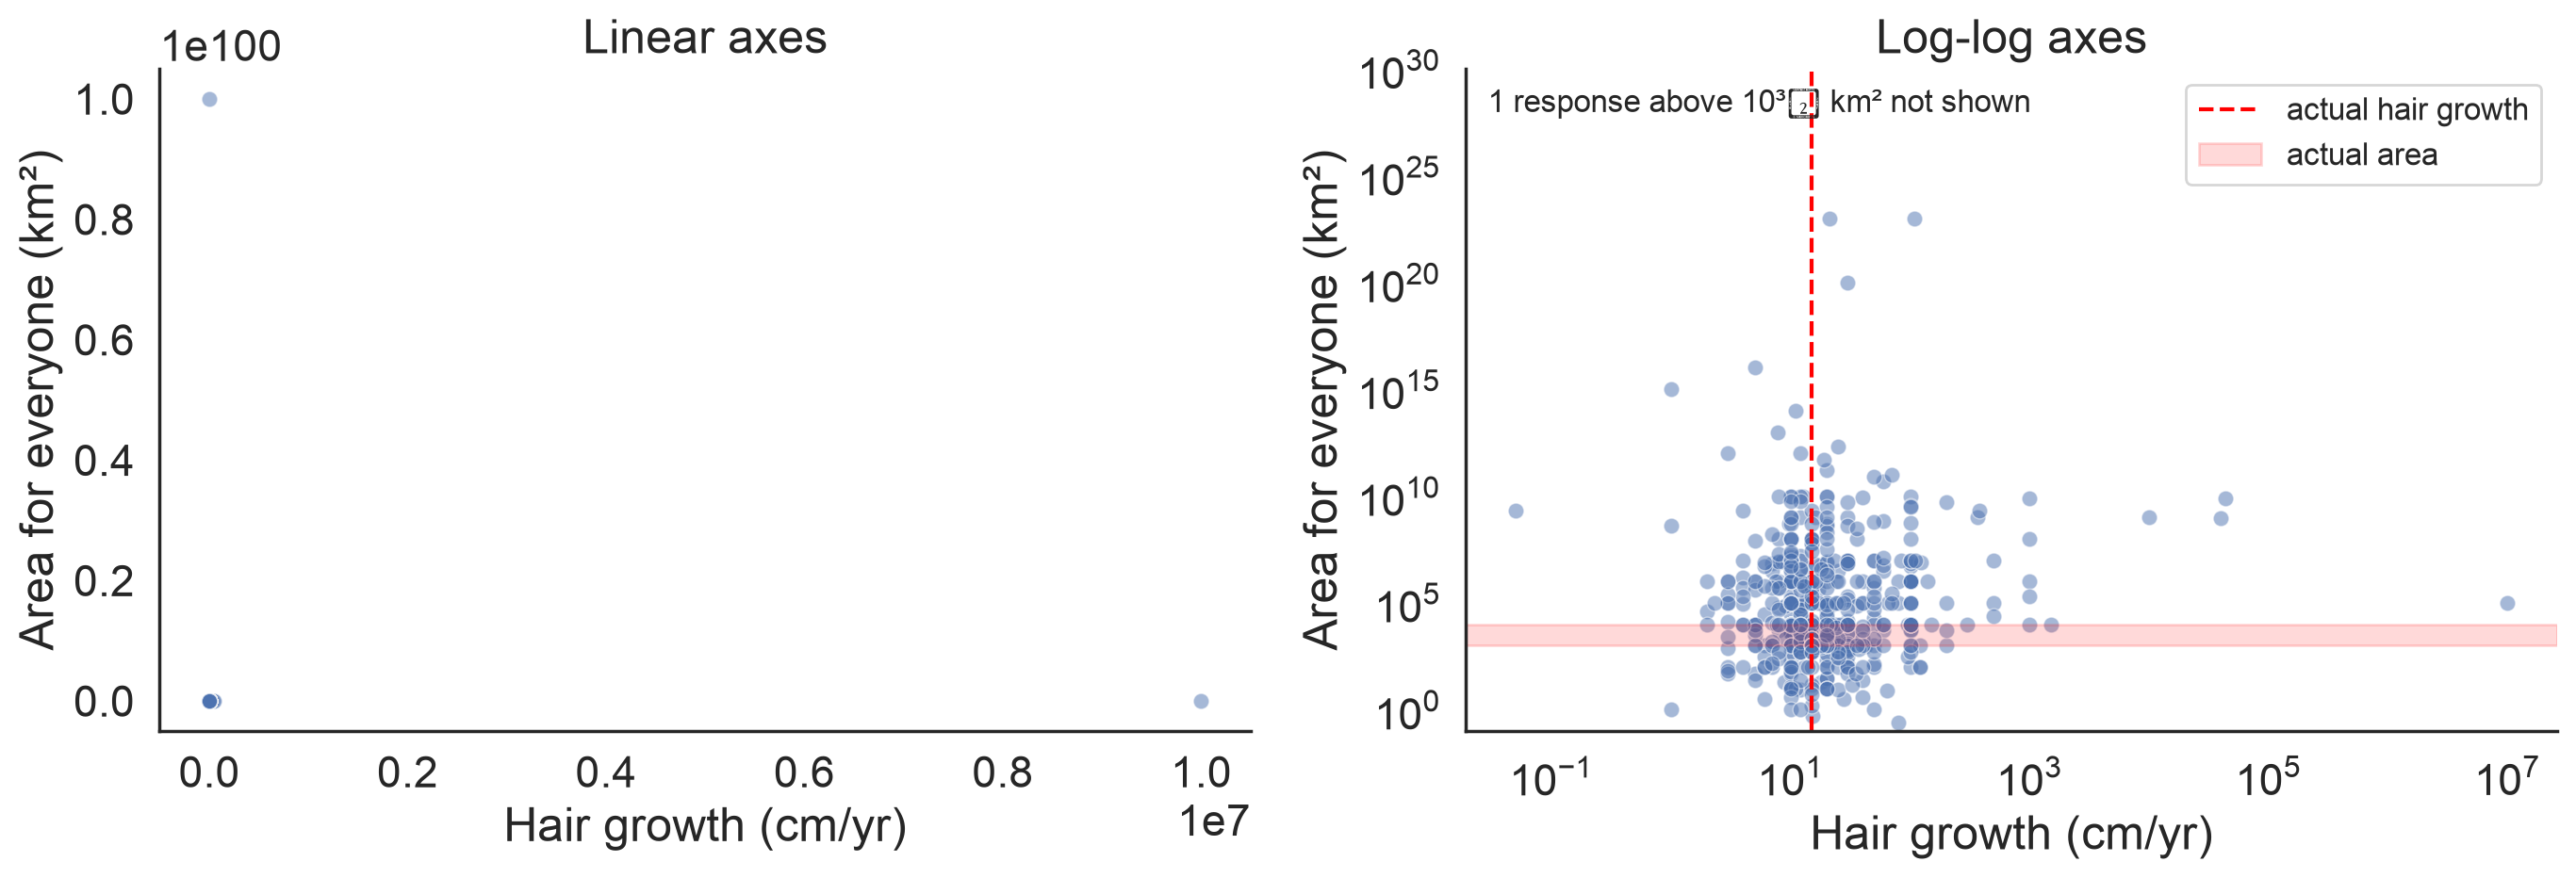

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# left: regular axes
sns.scatterplot(data=df, x='hair_cm_yr', y='area_km2', alpha=0.5, ax=ax1)
ax1.set(title='Linear axes', xlabel='Hair growth (cm/yr)', ylabel='Area for everyone (km²)')

# right: same data, log scale on both axes
sns.scatterplot(data=df, x='hair_cm_yr', y='area_km2', alpha=0.5, ax=ax2)
ax2.set(xscale='log', yscale='log', title='Log-log axes',
        xlabel='Hair growth (cm/yr)', ylabel='Area for everyone (km²)')

# zoom in: one response (10^100 km²) is so extreme it squashes everyone else, even on a log scale
ax2.set_ylim(1e-1, 1e30)
n_off = (df['area_km2'] > 1e30).sum()
ax2.text(0.02, 0.97, f'{n_off} response above 10³⁰ km² not shown', transform=ax2.transAxes,
         va='top', fontsize=12)

# mark the actual values
ax2.axvline(15, color='red', linestyle='--', label='actual hair growth')
ax2.axhspan(1_000, 10_000, color='red', alpha=0.15, label='actual area')
ax2.legend(loc='upper right', fontsize=12)

sns.despine()
plt.tight_layout()

In [31]:
# correlation between every pair of questions (on the log scale)
np.log10(df).corr().round(2)

,hair_cm_yr,area_km2,walk_days
hair_cm_yr,1.00,0.15,0.08
area_km2,0.15,1.00,0.08
walk_days,0.08,0.08,1.00


On regular axes, a few extreme answers squash every other point into a corner. On log-log axes (zoomed in past one 10<sup>100</sup> answer) we can see the whole class, but there's no clear pattern: all of the correlations are weak (≈0.15 or less). A student who was far off on one question wasn't necessarily far off on the others.

**Note:** `np.log10()` only works for positive values. That's fine here (every estimate is > 0), but check before you log-transform your own data.

## 13. EDA: A Recap <a id="s13"></a>

What we did today, in order:

| Step | Question it answers | Code | What we found in today's data |
|---|---|---|---|
| Look at the data | What is one row? Is it tidy? | `df`, `df.columns`, `df.dtypes`, `df.shape` | 514 responses × 3 questions; every column stored as text (`object`) |
| Check missingness | What's missing, and *why*? | `df.isnull().sum()`, `df[df.isnull().any(axis=1)]` | Nothing missing at first; after cleaning, 4 / 20 / 2 answers couldn't be read as numbers |
| Clean | Can these values be analyzed? | `.unique()`, `.apply(clean_fn)` | Free-text answers (units, words, `10^8`) converted to numbers |
| Shape & outliers | What's the range? Any extreme values? | `sns.catplot(..., kind='box')` on a log scale | Estimates span many orders of magnitude, with a few extreme values |
| Central tendency | What's a typical value? | `.mean()`, `.median()`, `.mode()` | Means pulled far off by outliers; medians were 15 cm/yr, 13,400 km², 60 days; modes were 10, 10,000, 30 |
| Variability | How spread out are the values? | `.max() - .min()`, `.quantile(0.75) - .quantile(0.25)`, `.var()`, `.std()` | Range, variance, and SD driven by a few extreme answers; the IQR is more useful here |
| Summarize | All of the above at once | `df.describe()` | Fast check for you, not a figure for your report |
| Relationships | Do two variables move together? | `sns.scatterplot()` with log axes, `.corr()` | Only weak relationships between the three questions |

- **Plot before you summarize.** Anscombe's Quartet: identical means, SDs, and correlations; very different data.
- **With skew or outliers, the median beats the mean** (and the IQR beats the SD) for describing typical values and spread.
- **Use log scales when values span orders of magnitude**, so a few extreme points don't hide everyone else.
- **Only remove outliers with a reason**, and say clearly in your report that you did.
- **Wisdom of the crowd?** The class median for hair growth matched the actual value (15 cm/yr); the median walking estimate (60 days) was in the right ballpark of ~38 days; the area median (13,400 km²) was the right order of magnitude (actual: 1,000–10,000 km²).

### Final Thoughts:

- If you just wanted to answer those three questions, your analysis would be complete with EDA alone. That said, your projects will require EDA...and additional analyses.
- When doing EDA your plots are to help you understand. Quick and dirty plots are fine. When you are writing a report, that's when you polish up your figures.  